In [23]:
import sys
import os
import json
from typing import NamedTuple
import math
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [24]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [25]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ss'
organism = 'worm-2025-fieseler'

In [26]:
file_id = 19
neuron_labels = ['VB02', 'SMDDR', 'DB01', 'AVAR']

In [27]:
manual = False

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [28]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymograph) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

traces = traces[mask]
continuous_behaviors = continuous_behaviors[mask]
eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]
kymograph = kymograph[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
pass

In [29]:
_, bom_man, bom_rec, bom_res, bom_pres, bom_resss, bom_bss = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)
_, hgm_man, hgm_rec, hgm_res, hgm_pres, hgm_resss, hgm_bss = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)

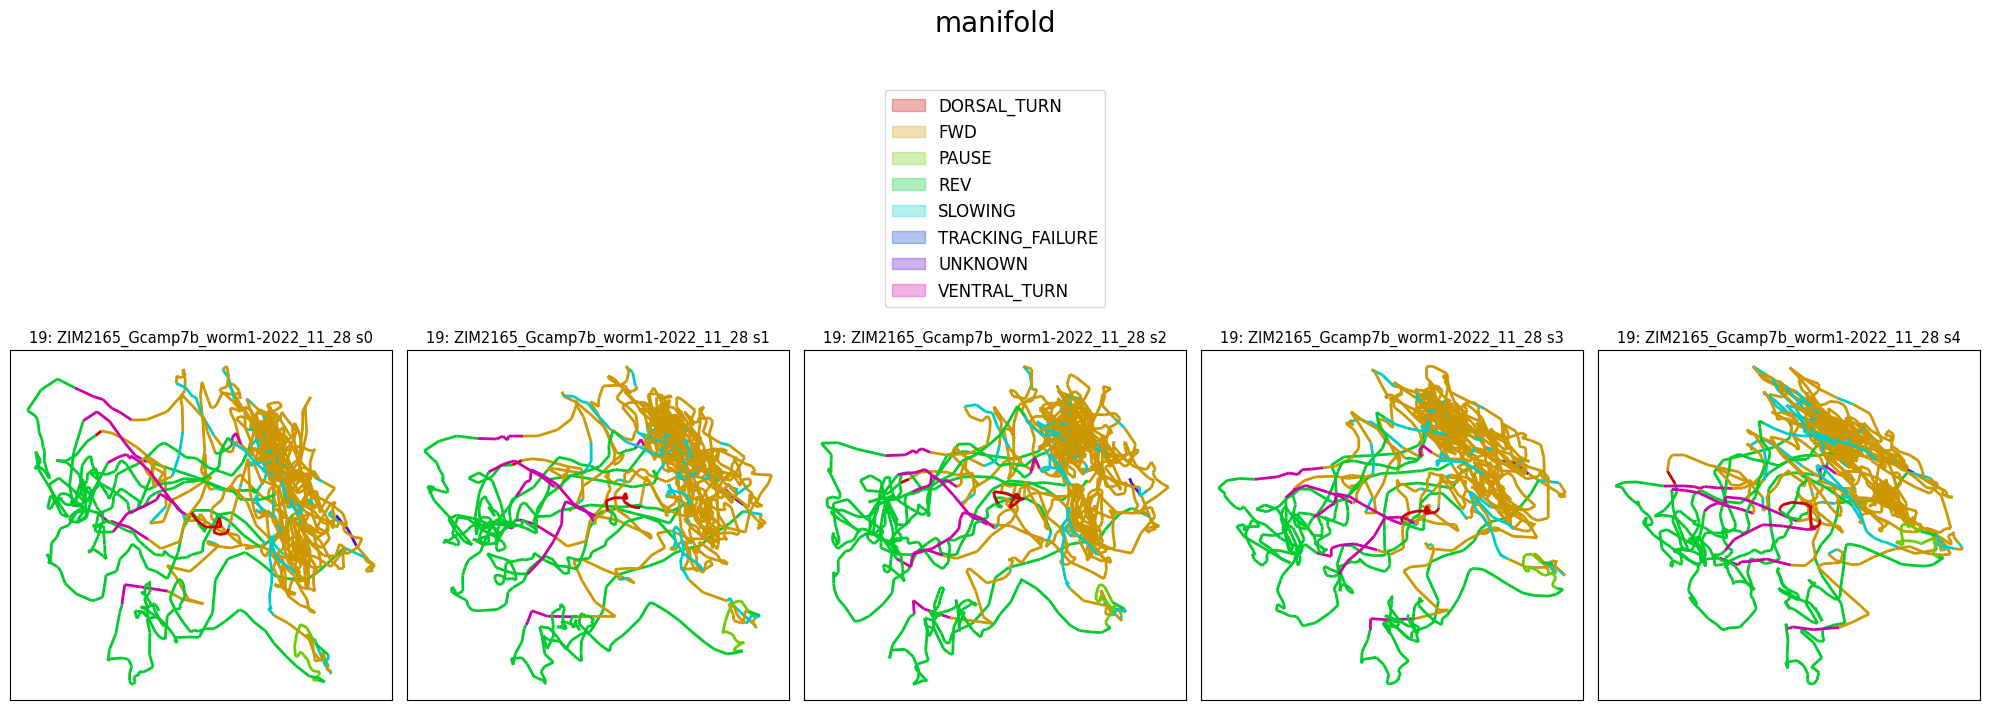

In [30]:
splits = 5
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
						  [hgm_man[s] for s in range(splits)],
						  [discrete_states for s in range(splits)],
						  None, None,
						  title='manifold', plots_per_row=splits, top_space=3.5,
						  save_path=None)

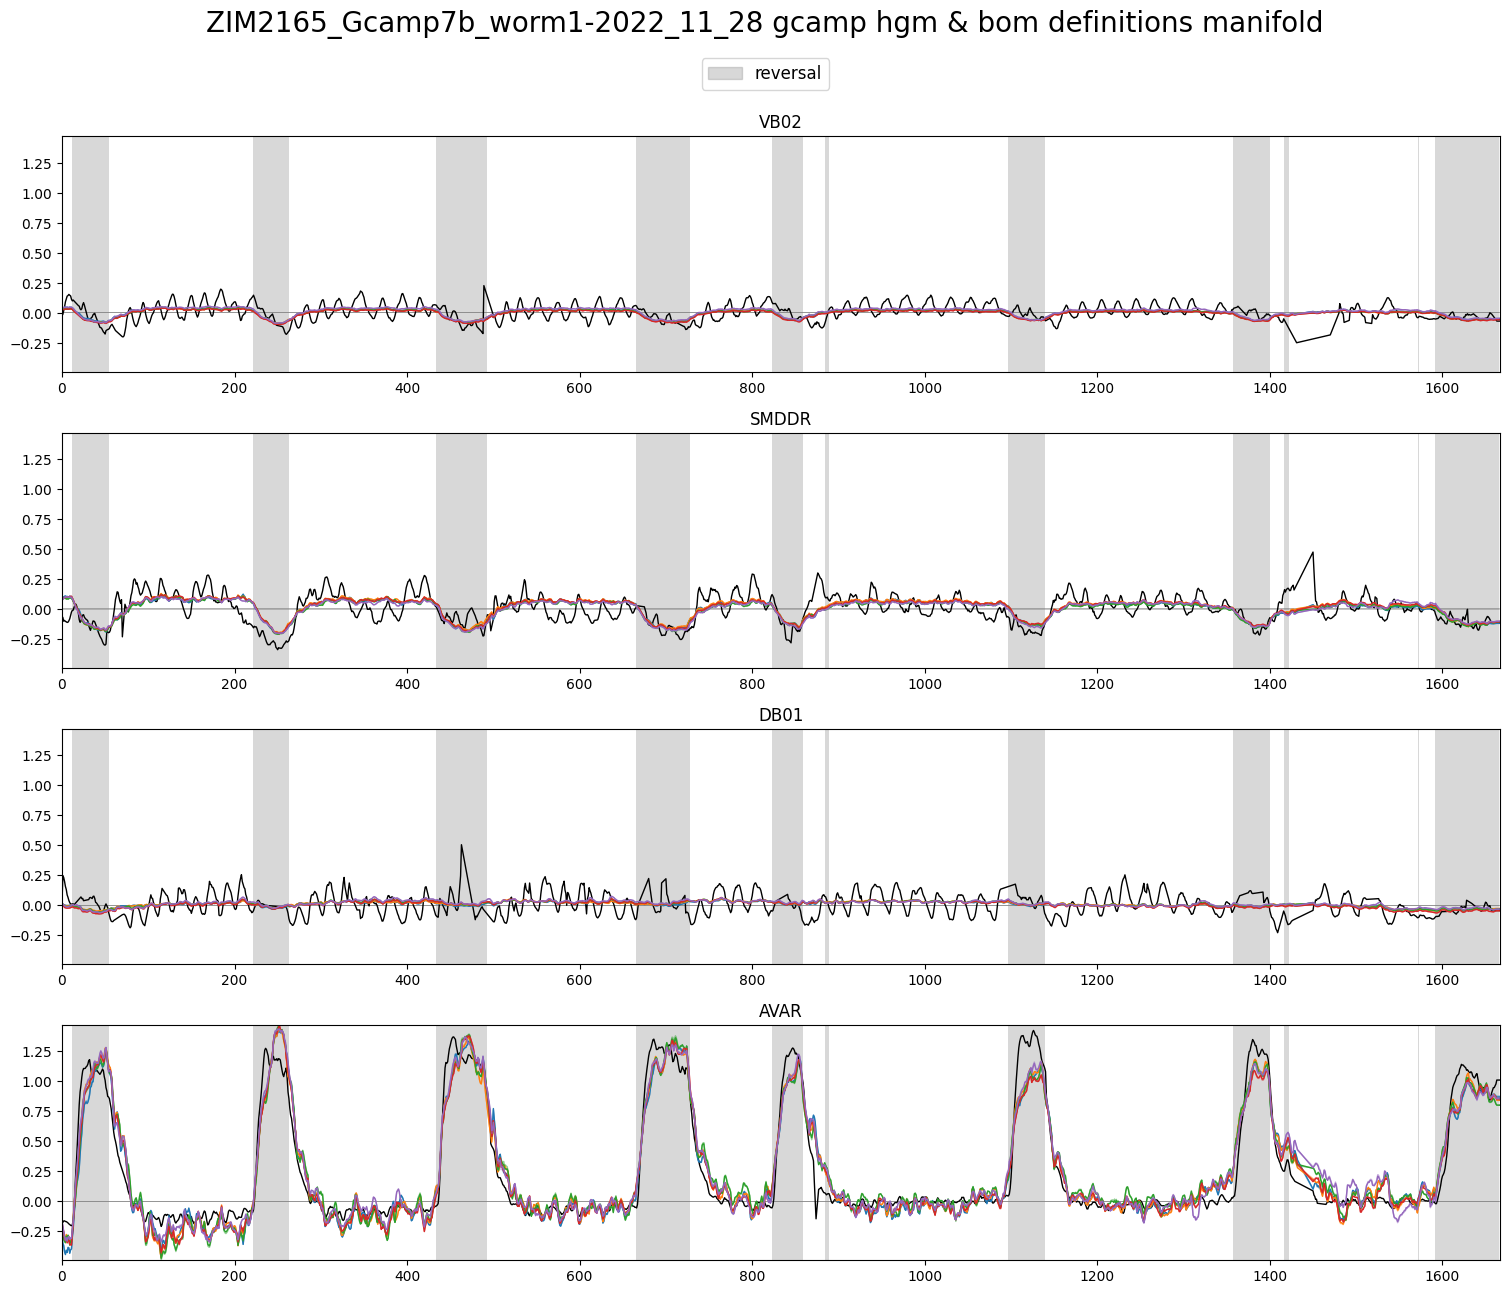

In [31]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_rec[i][neuron_labels] for i in range(splits)],
	[bom_rec[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	discrete_states[['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

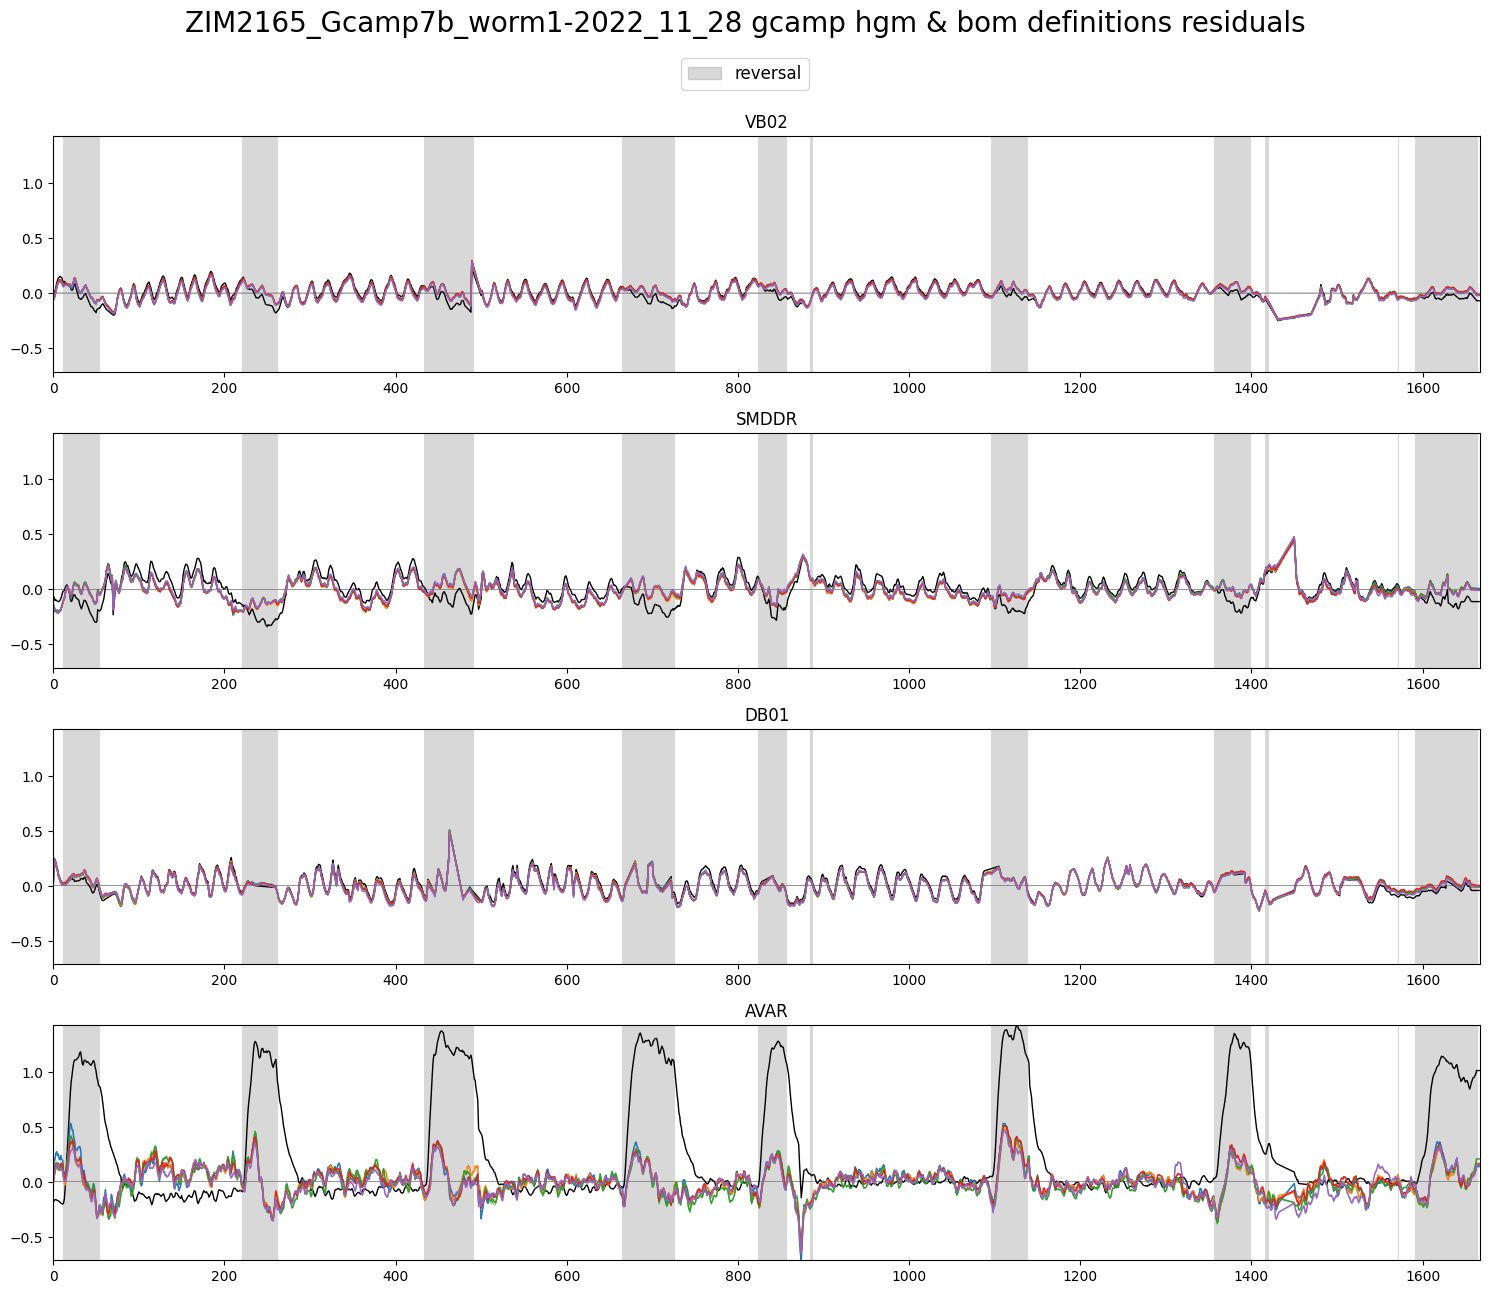

In [32]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_res[i][neuron_labels] for i in range(splits)],
	[bom_res[i][neuron_labels] for i in range(splits)],
	traces[neuron_labels],
	discrete_states[['REV']], label='reversal',
	title=f'{filename} gcamp hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

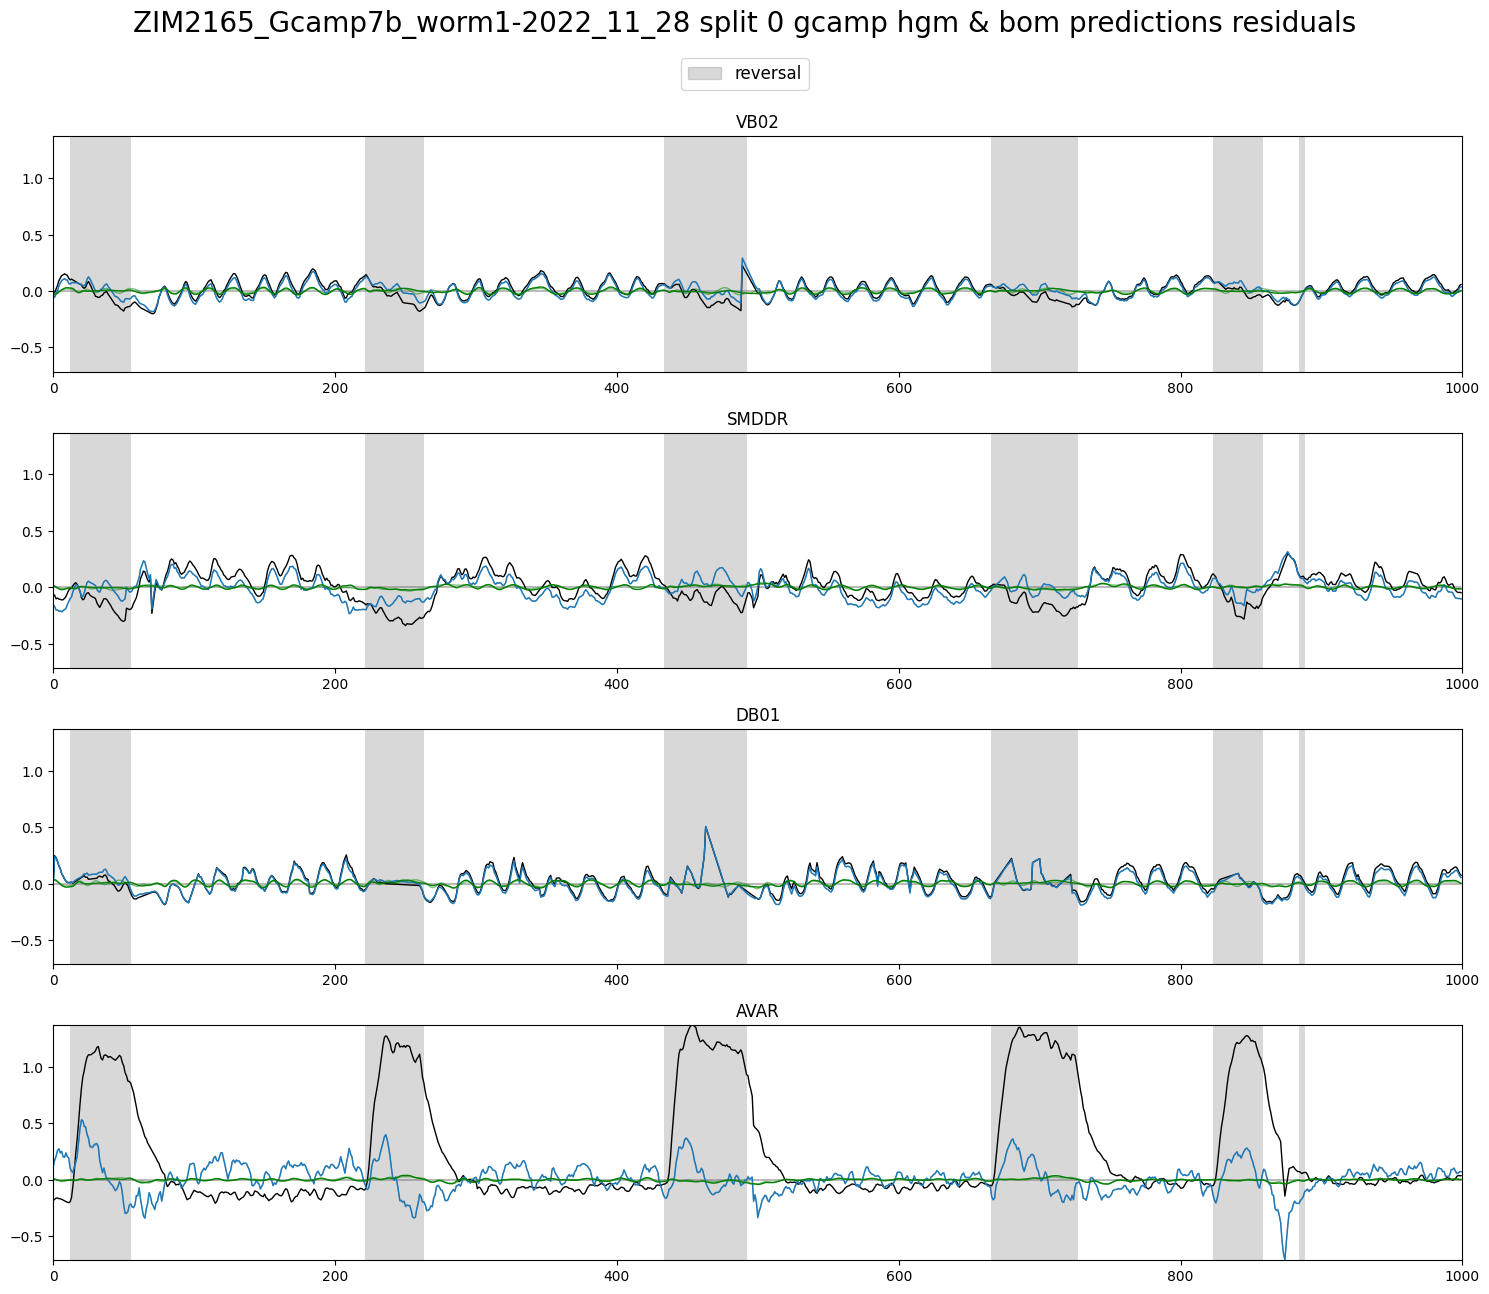

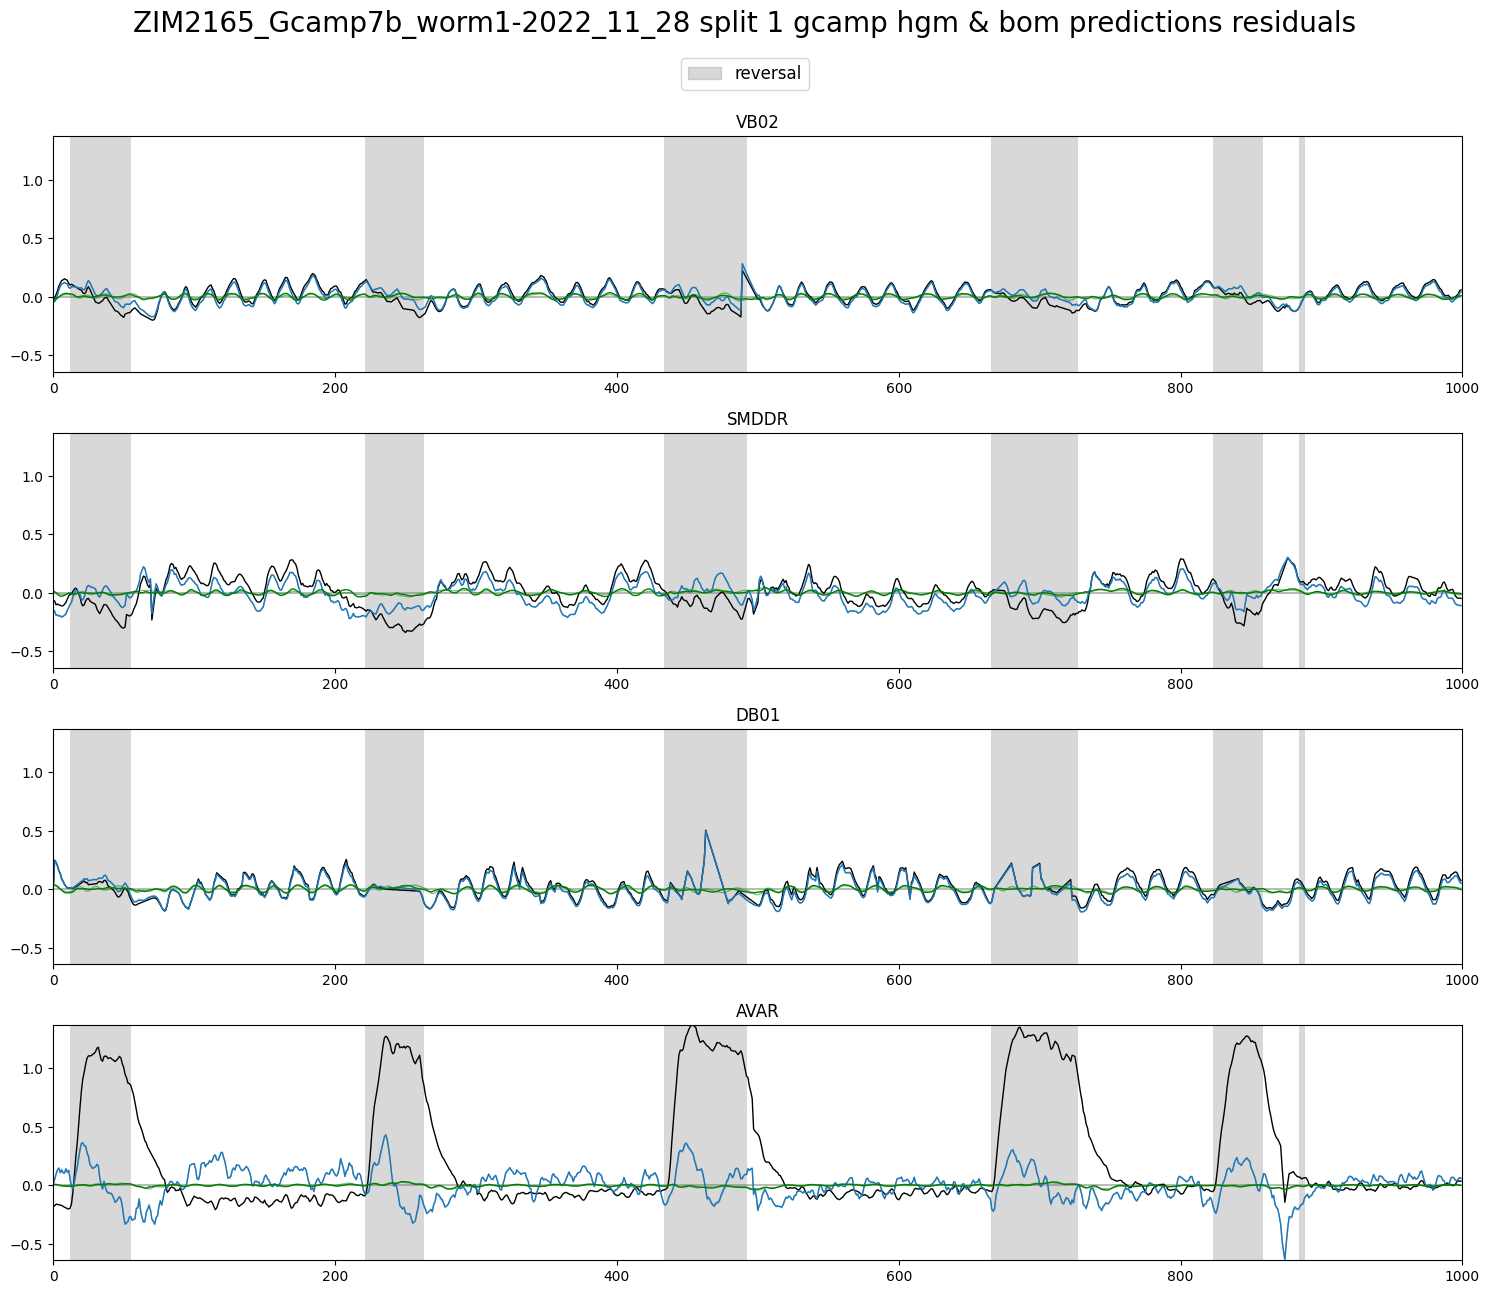

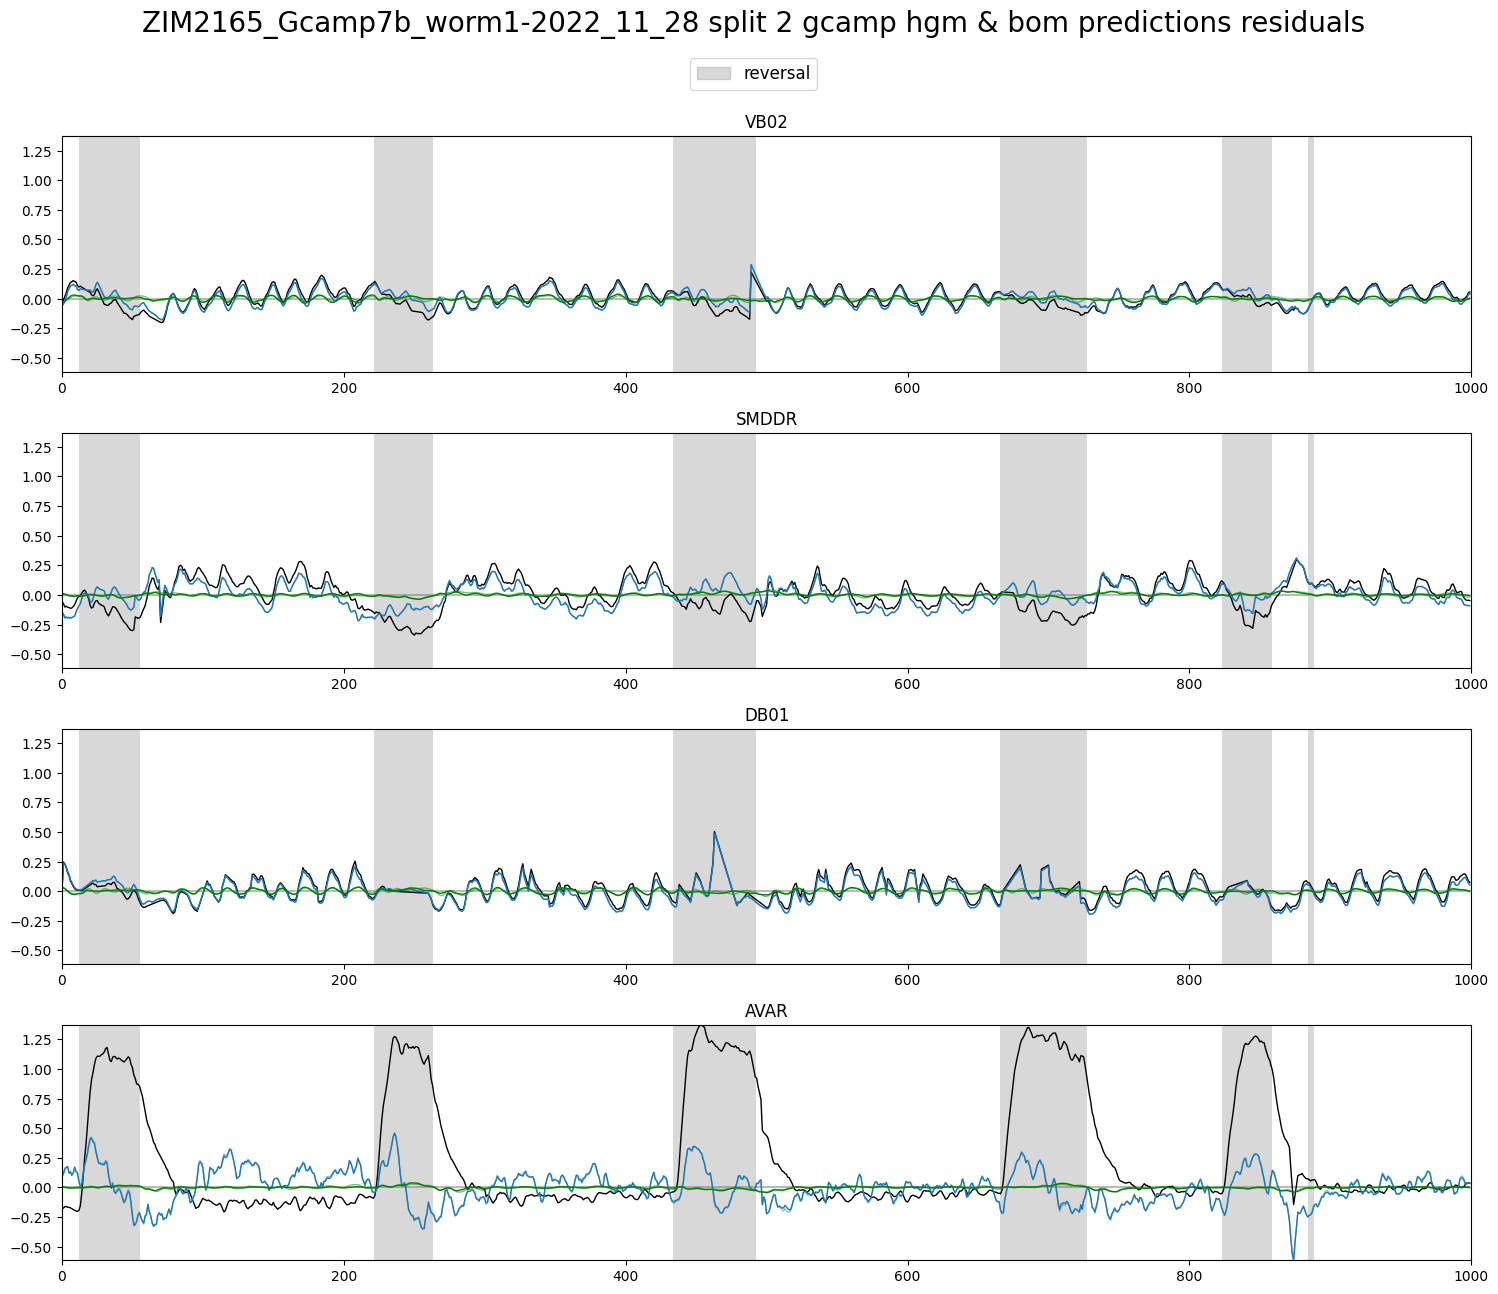

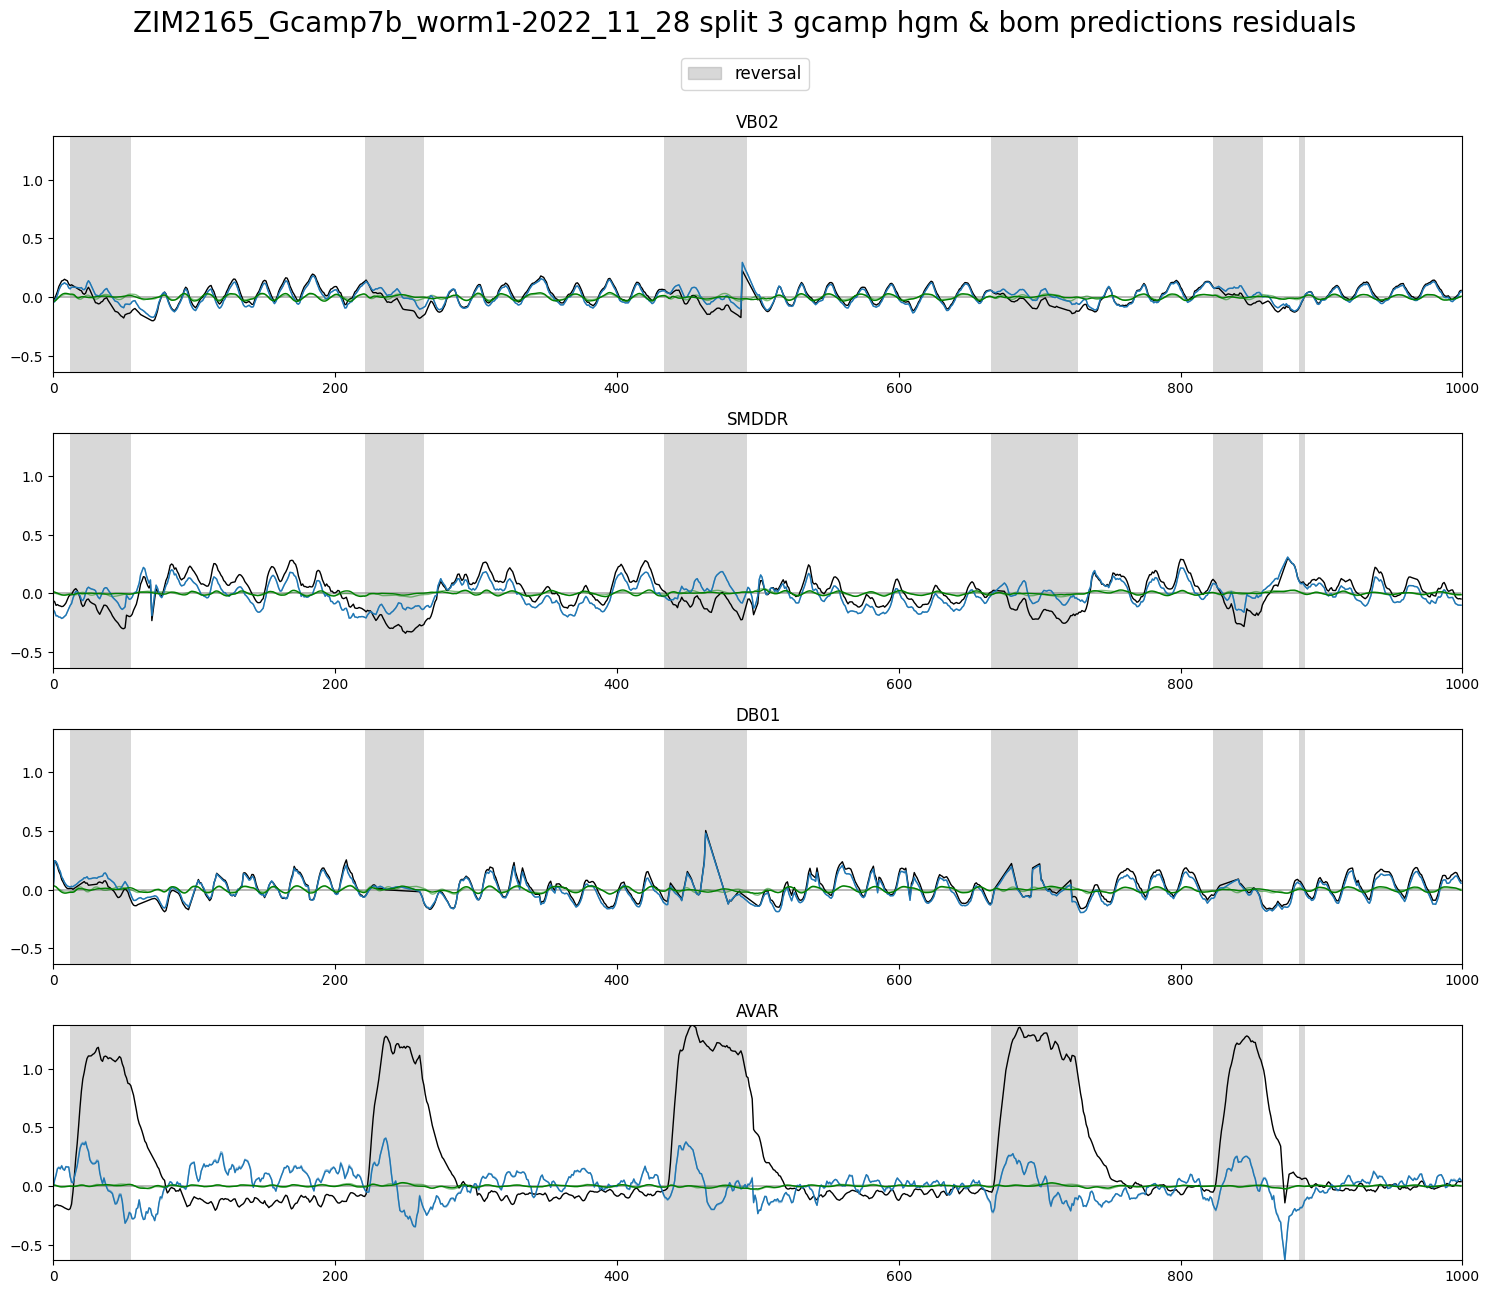

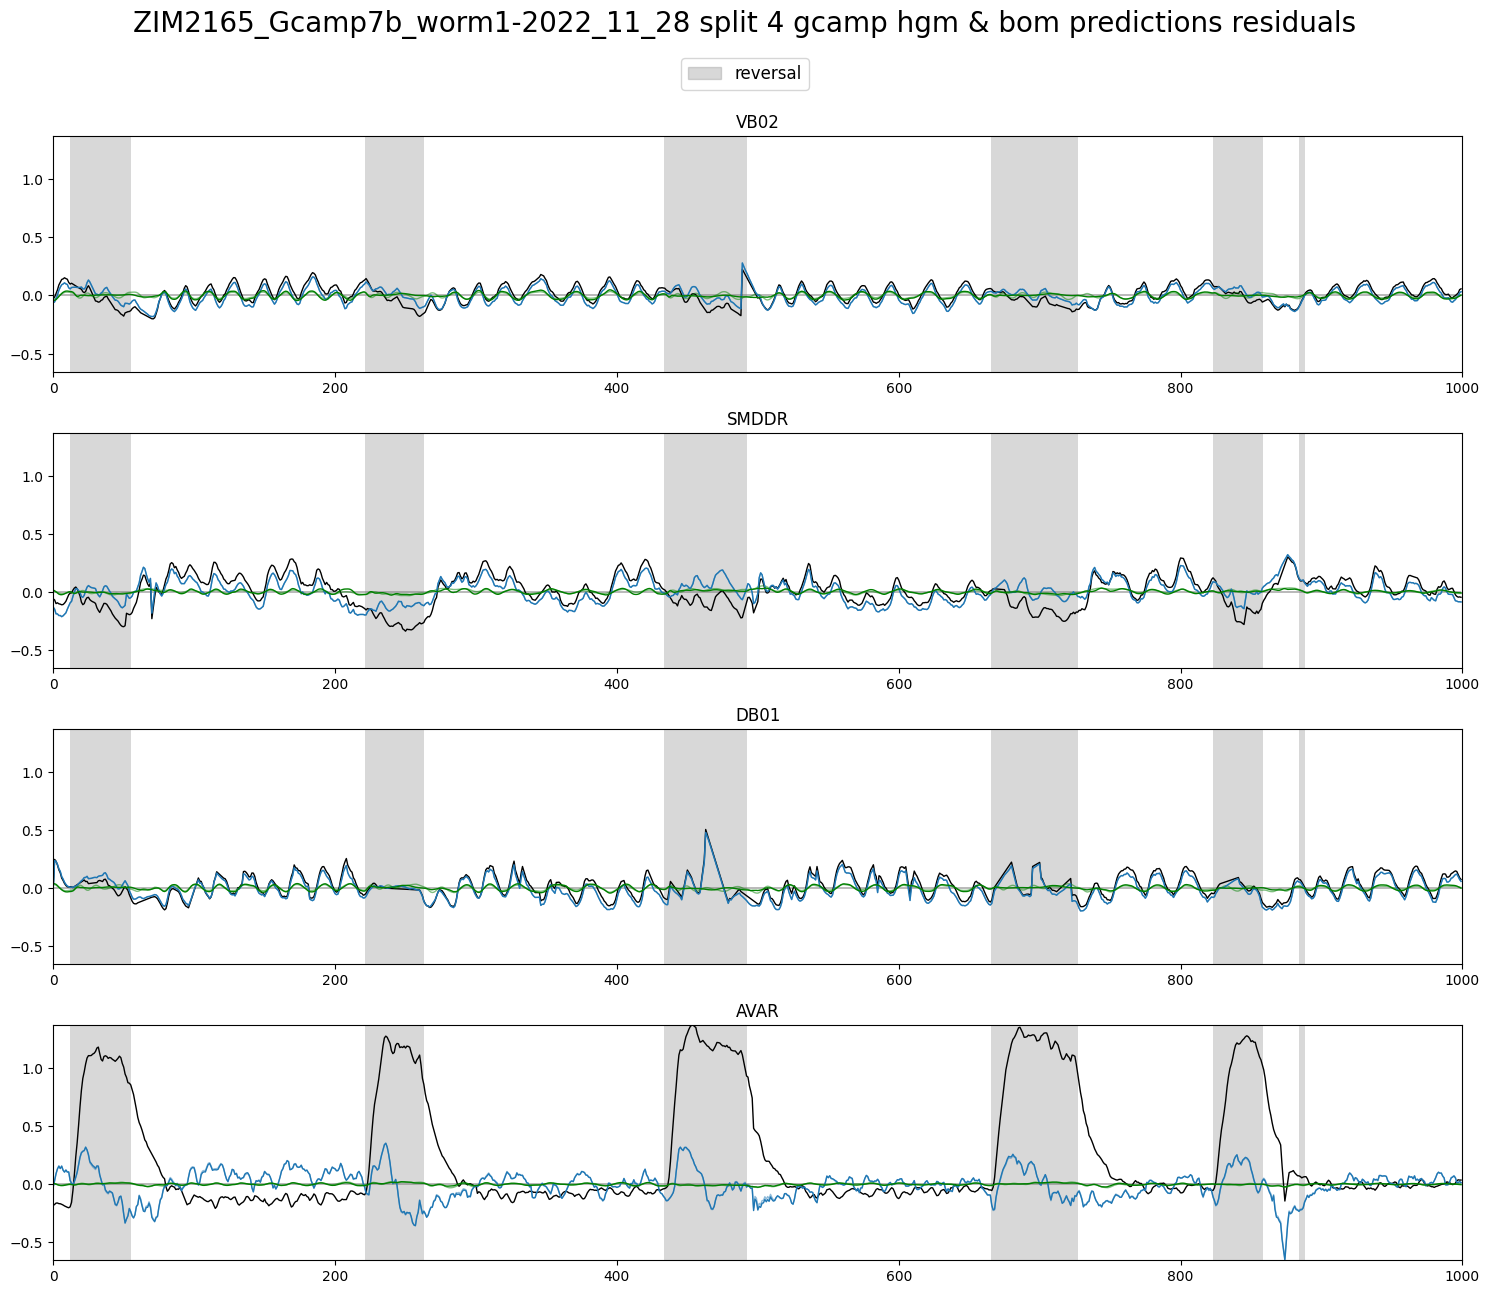

In [33]:
# max_x = traces.values.shape[0]
max_x = 1000

splits = 5
for i in range(splits):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[i][neuron_labels].iloc[:max_x, :],
		 hgm_pres[i][neuron_labels].iloc[:max_x, :]],
		[bom_res[i][neuron_labels].iloc[:max_x, :],
		 bom_pres[i][neuron_labels].iloc[:max_x, :]],
		traces[neuron_labels].iloc[:max_x, :],
		discrete_states[['REV']].iloc[:max_x, :], label='reversal',
		title=f'{filename} split {i} gcamp hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'

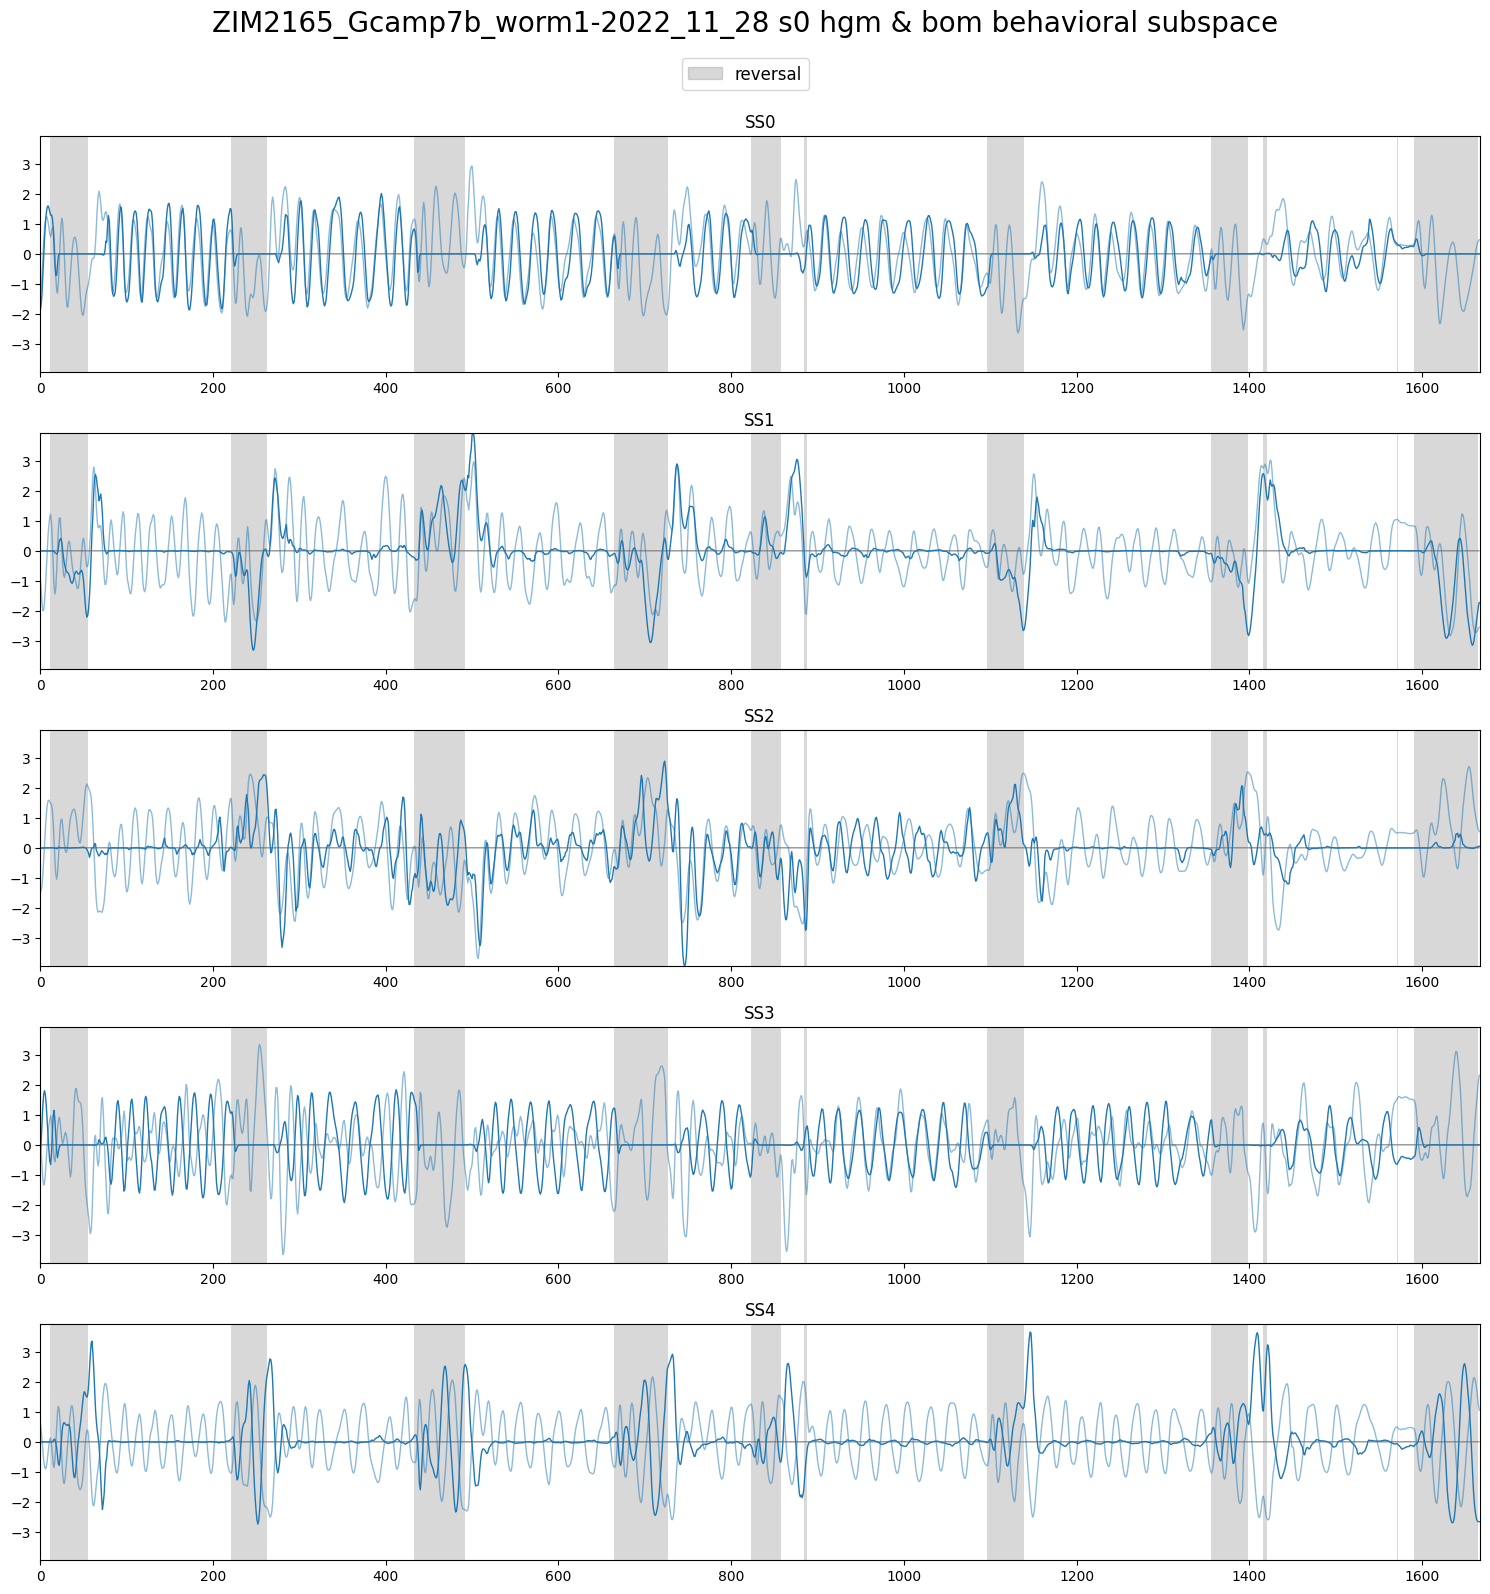

In [34]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_bss[i] for i in range(splits)][0:1],
	[bom_bss[i] for i in range(splits)][0:1],
	None,
	discrete_states[['REV']], label='reversal',
	title=f'{filename} s0 hgm & bom behavioral subspace', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_BSS'

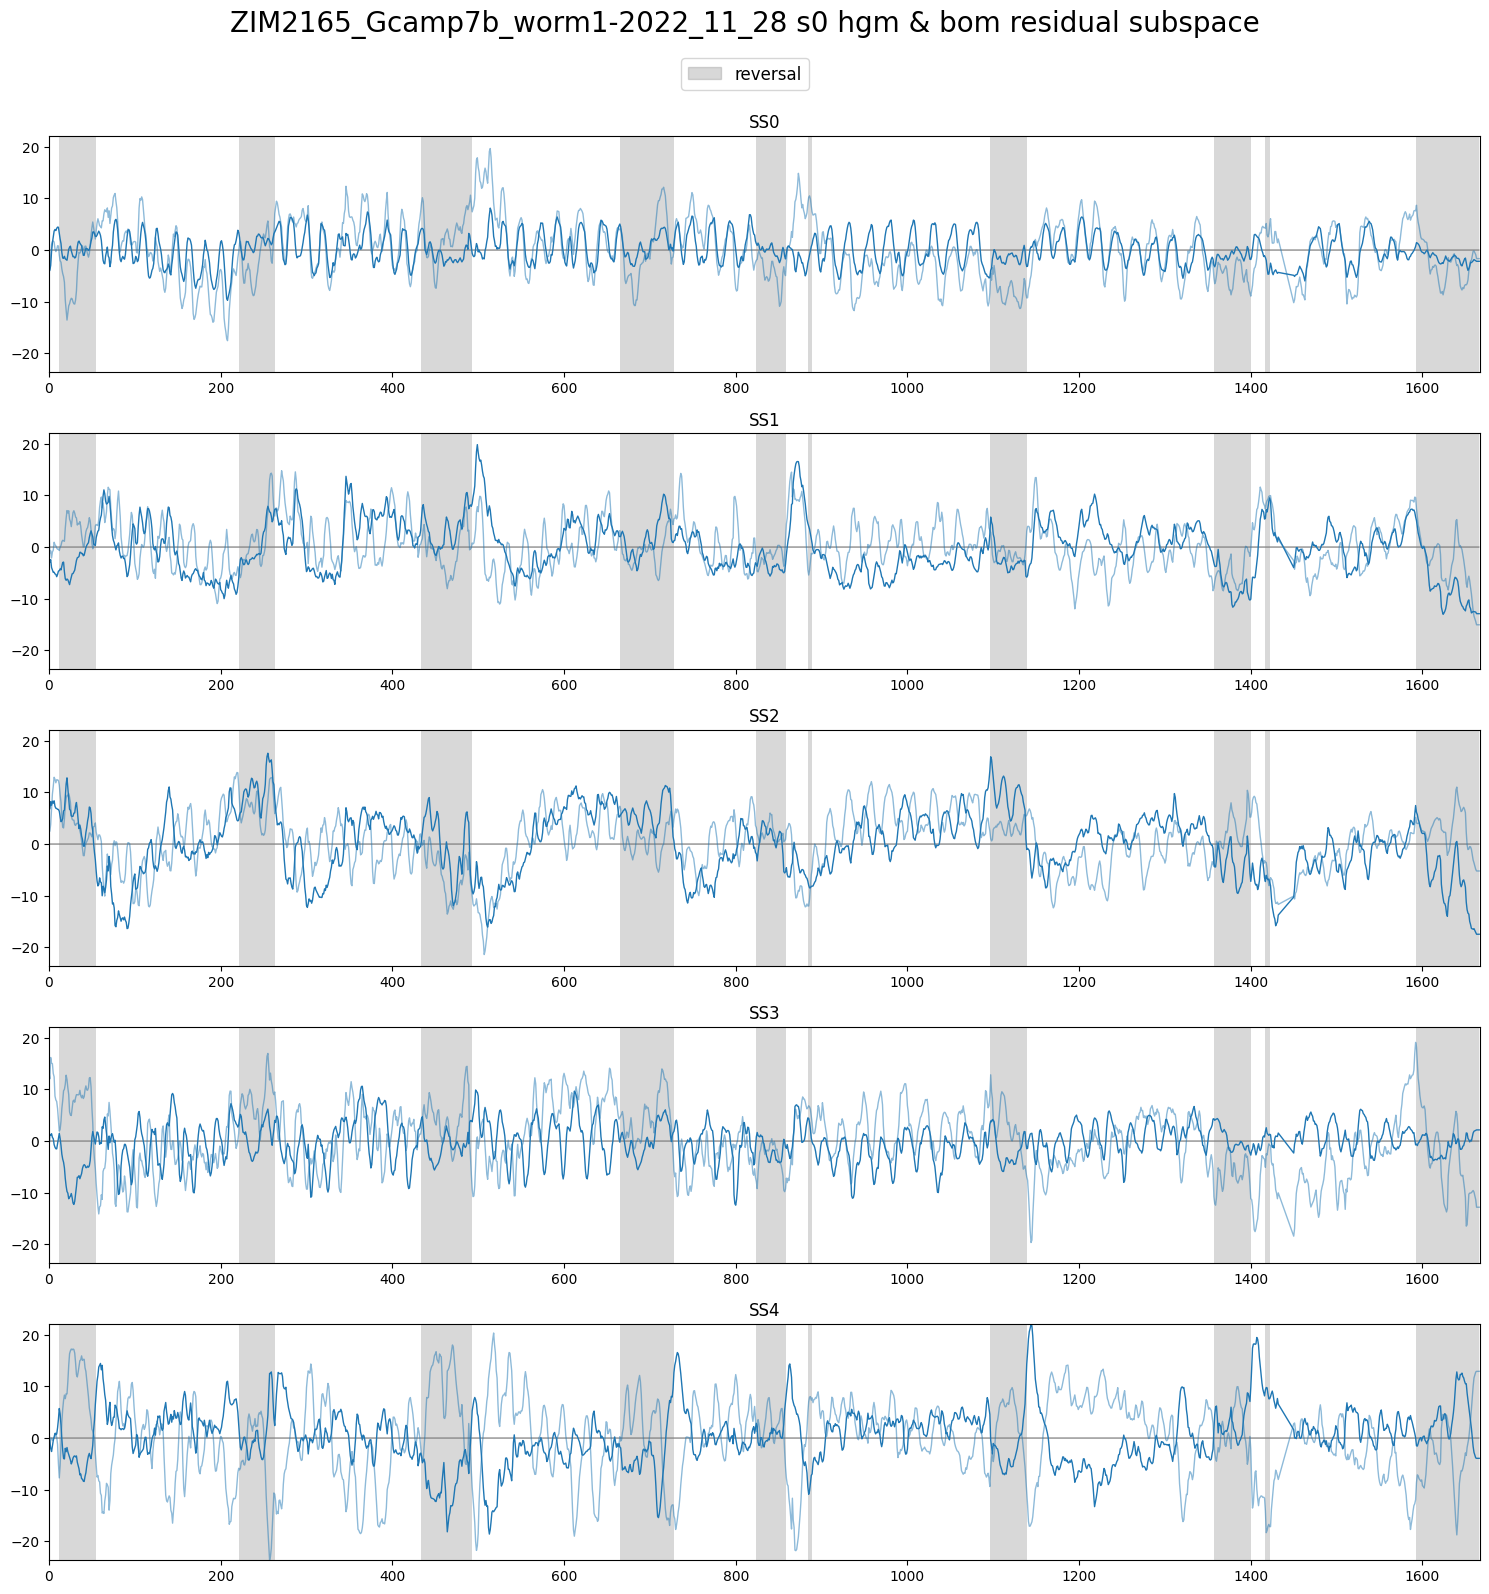

In [35]:
splits = 5
plot_utils.plot_traces_splits(
	[hgm_resss[i] for i in range(splits)][0:1],
	[bom_resss[i] for i in range(splits)][0:1],
	None,
	discrete_states[['REV']], label='reversal',
	title=f'{filename} s0 hgm & bom residual subspace', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RESSS'

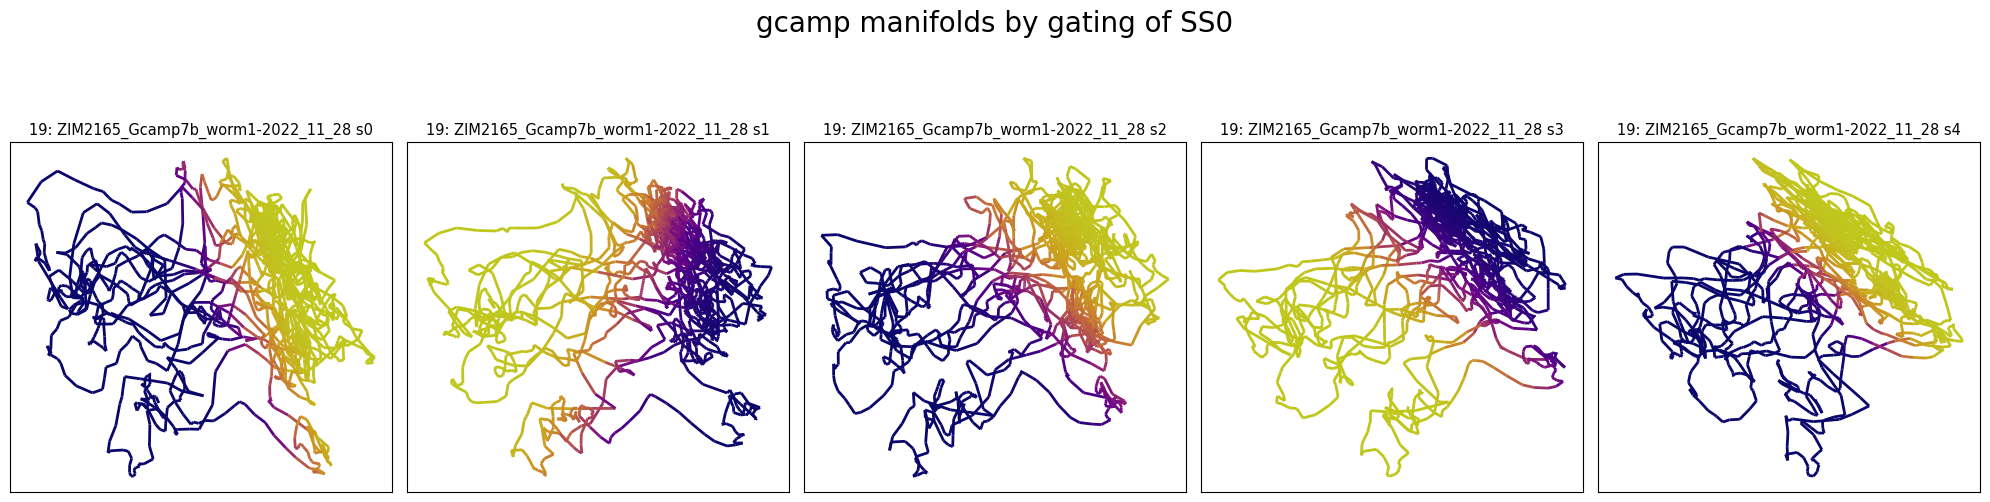

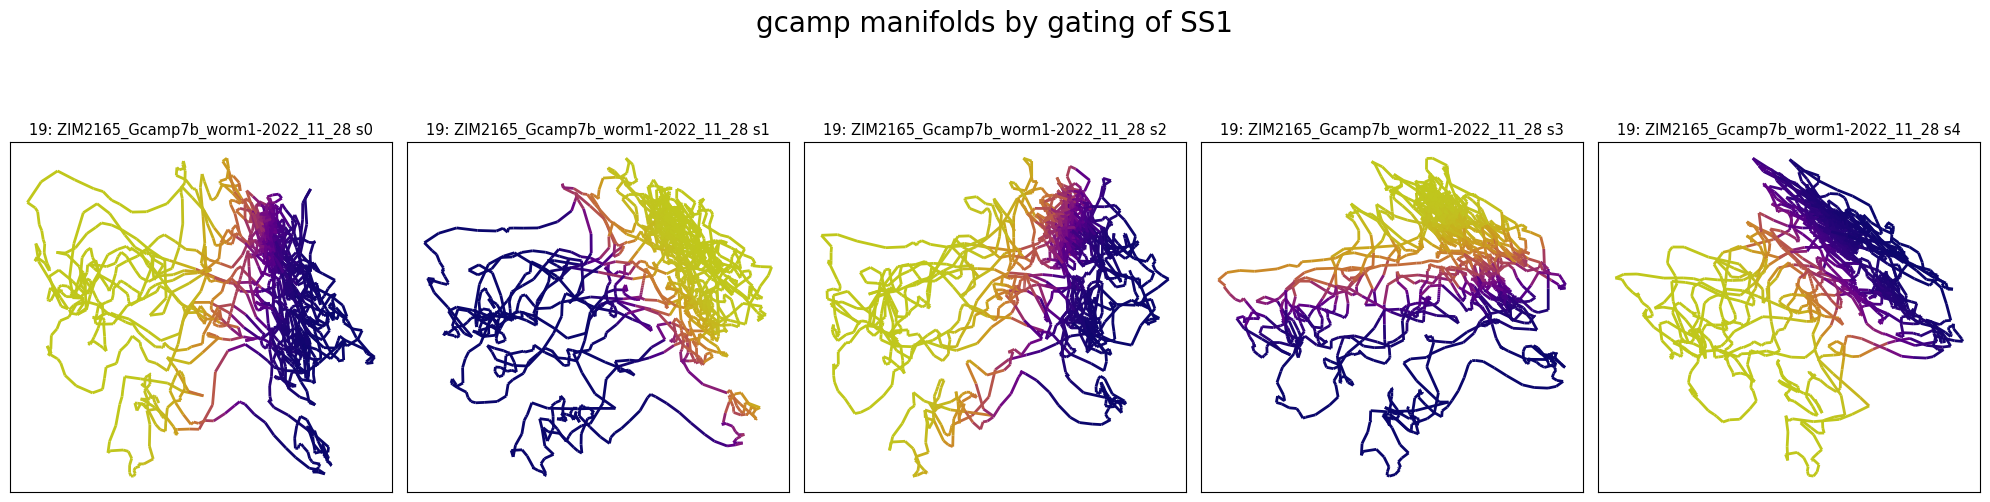

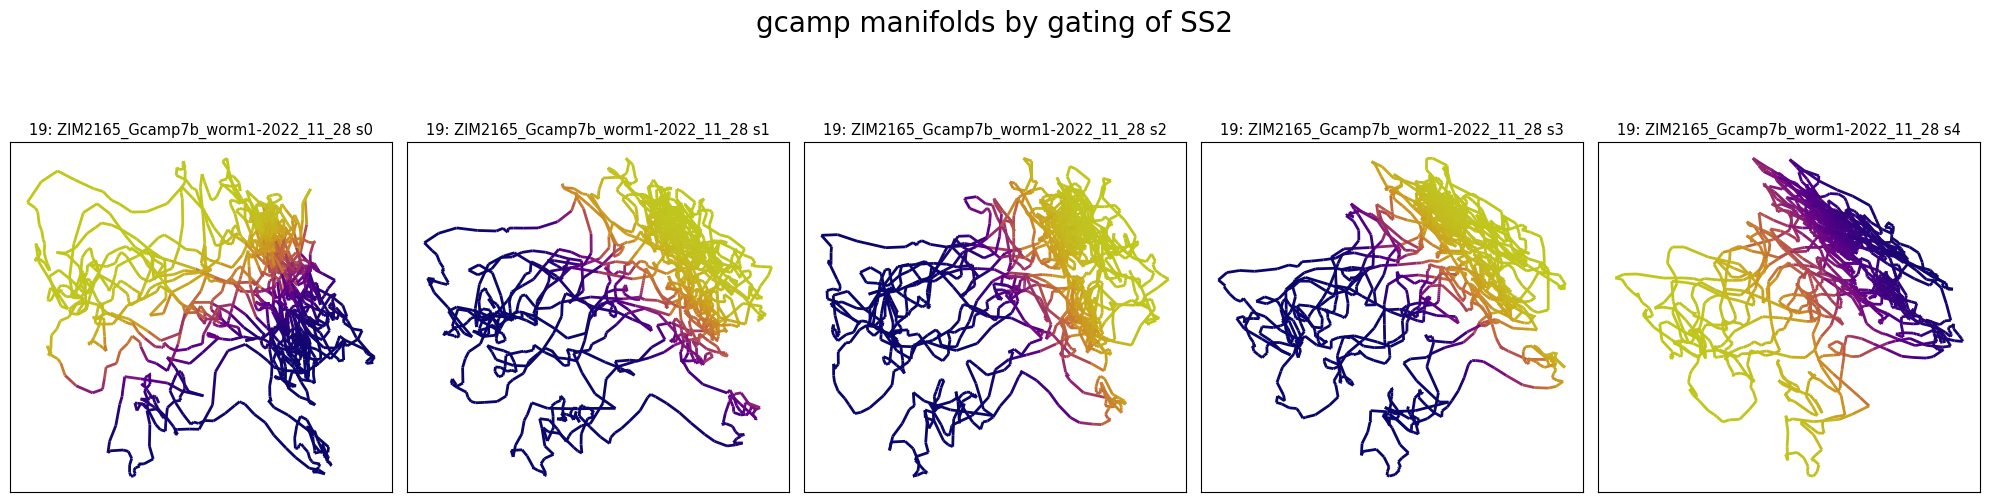

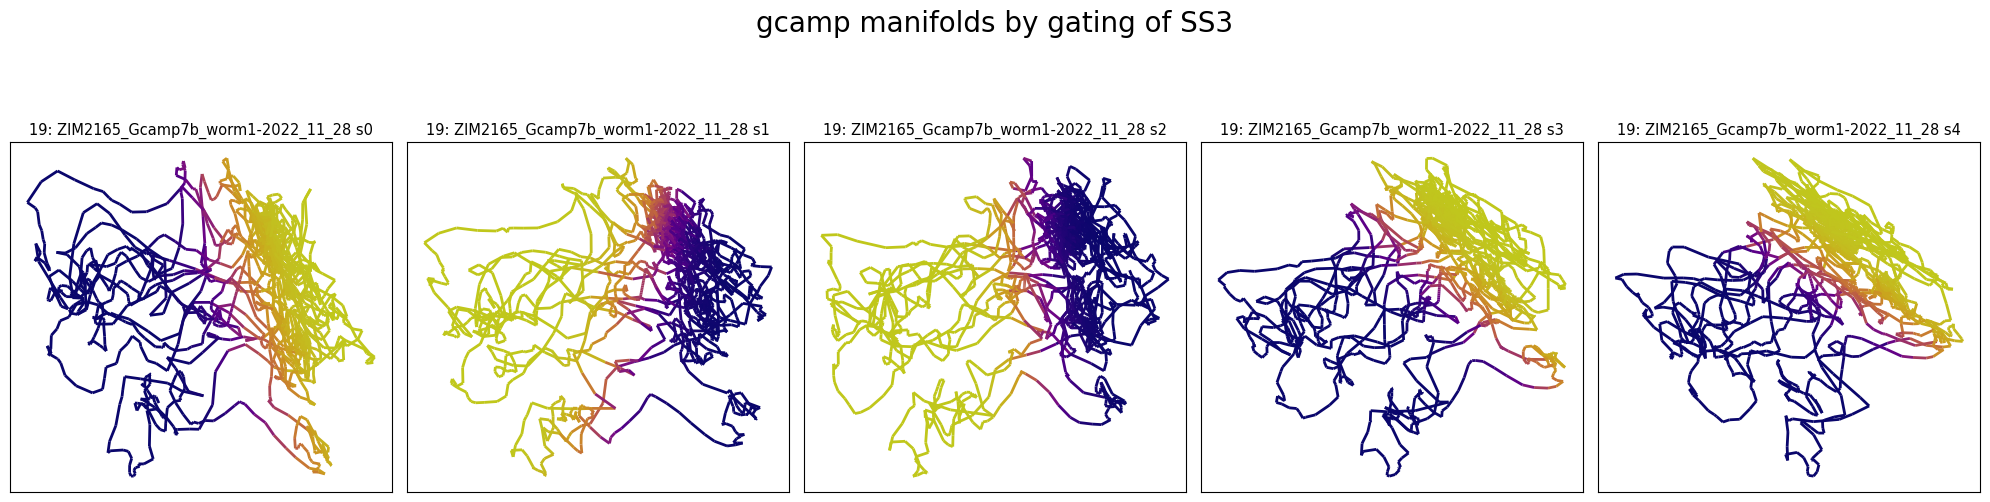

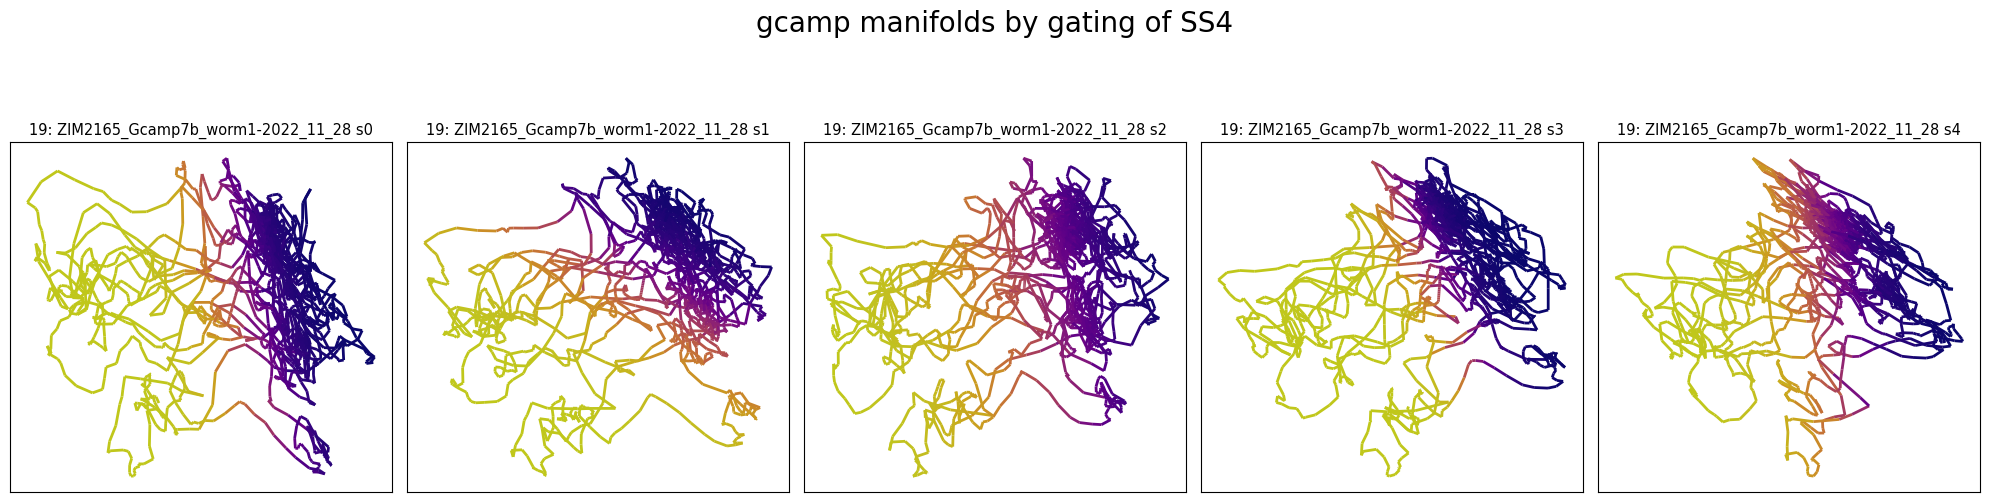

In [36]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

hgm_folder = f'{data_variant}_hgm_{model_variant}_' + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()])
hgm_params = train_utils.load_params(os.path.join(f'{read_utils.get_model_path()}', 'params', hgm_folder), filename)

sss = [f'SS{i}' for i in range(hgm_resss[0].shape[1])]
ss_ids = [hgm_resss[0].columns.get_loc(ss) for ss in sss]

splits = 5

for ss_id in ss_ids:
	sigmoid_terms = list()
	for split in range(splits):
		manifold_term = hgm_man[split].values
		manifold_term_zs = (manifold_term - manifold_term.mean(axis=0)) / np.where((N_std := manifold_term.std(axis=0)) == 0.0, 1.0, N_std)

		WM = hgm_params[split]['model']['WM'][:, ss_id]

		sigmoid_term = sigmoid(manifold_term_zs @ WM)
		sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
							  [hgm_man[s] for s in range(splits)],
							  [sigmoid_terms[s] for s in range(splits)],
							  None, None,
							  title=f'gcamp manifolds by gating of {hgm_resss[0].columns[ss_id]}', plots_per_row=splits, top_space=1,
							  save_path=None)